# NB\_C09: Synthesis and Mathematical Perspectives

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C09_Synthesis_Perspectives.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 10 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.18 and GPT-5.4

---

## Talk Framing

**One-sentence takeaway:** this capstone series builds a first
patient-specific **glioma brain digital twin** for PAT16, then asks which
parts of that chain are already evidence-supported, which remain
provisional, and what mathematical advances are needed before the twin can
become genuinely predictive.

The previous notebooks established the separate pieces of the twin:
anatomy, segmentation, diffusion-informed structure and material
properties, resting-state functional observations, brain mechanics,
whole-brain neural dynamics, and postoperative cognitive and psychosocial
outcomes. This notebook is therefore not a new modality notebook. It is a
**synthesis notebook** whose job is to show how those pieces fit together
as one coupled model.

The central issue is calibration of ambition. In glioma, the appeal of a
digital twin is obvious: tumour geometry, surgical cavity formation, brain
shift, tract disruption, network reorganisation, cognition, and
psychosocial burden can all be observed in the same patient over time. But
that does **not** mean the current proof-of-concept already supports
individual prediction or clinical decision support. The value of this final
chapter is to make that distinction explicit.

## Objectives

- Consolidate the coupling chain parameters and key results
- Identify mathematical challenges in brain mechanics and neural dynamics
- Distinguish what is evidence-based from what remains provisional
- Reframe the path from proof-of-concept to clinical translation as a research roadmap

**Prerequisites:** All previous notebooks in the capstone series

---
## 1. What the Current Glioma Brain Digital Twin Actually Contains

The present PAT16 twin is best understood as a **layered,
partly data-driven and partly mechanistic model**. Some parts are measured
directly from MRI or clinical assessment; some are inferred through image
processing; and some are represented through explicit mathematical models.
The twin is therefore not yet a continuously updated closed-loop clinical
system. It is a structured proof-of-concept that links the most important
observable layers of the glioma problem in one patient.

### The six linked layers

| Layer | Measured data | Model or transformation | Main output | Main uncertainty |
|---|---|---|---|---|
| **1. Anatomy** | T1w MRI, lesion and cavity masks | segmentation, parcellation, mesh generation | patient-specific geometry | segmentation and registration error |
| **2. Tissue properties** | diffusion MRI (FA, MD) | heuristic mapping from diffusion scalars to elastic parameters | heterogeneous stiffness and compressibility fields | biological validity of FA $\to E$ and MD $\to \nu$ mappings |
| **3. Structural network** | tractography from diffusion MRI | DK68 parcellation + SIFT2 weighting | 68$\times$68 structural connectivity matrix | tractography bias and missing pathways |
| **4. Functional observation** | resting-state fMRI | regional time series + Pearson FC | empirical FC target | BOLD is indirect and physiologically noisy |
| **5. Mechanics and dynamics** | pre-op and post-op images constrain the models | FEM displacement field + Hopf whole-brain dynamics | deformation, SC perturbation, simulated FC | parameter identifiability and model mismatch |
| **6. Clinical outcome** | CANTAB and psychosocial measures | domain mapping and postoperative comparison | interpretable validation targets | cognition is influenced by many non-structural factors |

### What is patient-specific here

Several parts of the twin are already genuinely patient-specific: the
anatomy, lesion location, resection cavity, structural connectivity,
empirical functional connectivity, and observed postoperative cognitive and
psychosocial profile all come from **sub-PAT16**. This is one reason
why glioma is such a compelling digital-twin setting: the same patient can
be followed across anatomical, mechanical, network, and behavioral levels.

### What is modeled, inferred, and measured

A useful distinction is:

- **measured**: T1w anatomy, diffusion MRI, resting-state fMRI, cognitive and psychosocial outcomes
- **inferred**: segmentations, parcellations, tractography-based SC, empirical displacement from registration
- **modeled**: elasticity, mechanics-driven SC perturbation, bifurcation shifts, Hopf dynamics, domain-level vulnerability

This distinction matters because later sections discuss not only what the
pipeline can do, but also where the assumptions become strongest.

### What has been demonstrated in PAT16

Across `NB_C03` to `NB_C08`, the series has shown that the coupling chain
can be assembled **end-to-end** for one patient:

1. **Patient-specific geometry** from T1w segmentation $\to$ FE mesh (`NB_C03`)
2. **Diffusion-informed material heterogeneity** from FA and MD (`NB_C04`)
3. **Structural connectivity** from SIFT2-weighted tractography (`NB_C04`)
4. **Functional connectivity** from resting-state fMRI (`NB_C05`)
5. **Brain mechanics** with substantial reduction of the displacement gap (`NB_C06`)
6. **Hopf whole-brain dynamics** on the patient-specific connectome (`NB_C07`)
7. **Mechanics-to-dynamics coupling** through SC modulation and bifurcation shift (`NB_C07`)
8. **Comparison to postoperative cognition** using domain-level vulnerability (`NB_C08`)

That is already a meaningful result. What it does **not** yet establish is
that the current twin is sufficiently identified, robust, and generalizable
to support patient-level prediction outside this proof-of-concept.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import pandas as pd
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

FIG_DIR = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

---
## 2. Coupling Assumptions and Parameters

The table below collects the main links in the present coupling chain,
along with their working values and biological motivations. It is useful as
an engineering summary, but it should **not** be read as if every quantity
were equally well constrained by patient data.

Some entries are close to measured inputs or directly derived from the
processing pipeline. Others are best thought of as **working assumptions**
that make the proof-of-concept operational. A central task for the next
version of the twin is therefore to move more of these assumptions from
"plausible" toward "identified and validated."

In [2]:
summary = pd.DataFrame([
    {'Coupling': 'Tissue segmentation \u2192 FE mesh',
     'Parameter': '--', 'Value': '192k tets, 45k nodes',
     'Biological basis': 'FreeSurfer aparc+aseg \u2192 5 tissue classes'},
    {'Coupling': 'FA \u2192 Young\'s modulus',
     'Parameter': '\u03b1_FA', 'Value': '0.8',
     'Biological basis': 'Axonal density increases stiffness'},
    {'Coupling': 'MD \u2192 Poisson\'s ratio',
     'Parameter': '\u03b2_MD', 'Value': '0.05',
     'Biological basis': 'Water content modulates compressibility'},
    {'Coupling': 'Tumour pressure \u2192 body force',
     'Parameter': 'p\u2080', 'Value': '1500 Pa',
     'Biological basis': 'Glioma interstitial pressure (10-25 mmHg)'},
    {'Coupling': 'Force decay length',
     'Parameter': 'L', 'Value': '15 mm',
     'Biological basis': 'Tissue compliance spatial decay'},
    {'Coupling': 'Displacement \u2192 SC reduction',
     'Parameter': '\u03b1_SC', 'Value': '2.0',
     'Biological basis': 'Axonal stretch reduces conduction'},
    {'Coupling': 'Displacement \u2192 excitability',
     'Parameter': '\u03b2_bif', 'Value': '0.15',
     'Biological basis': 'Compression shifts E/I balance'},
    {'Coupling': 'SC \u2192 neural dynamics',
     'Parameter': 'J', 'Value': '0.05',
     'Biological basis': 'Global coupling strength'},
    {'Coupling': 'Base bifurcation',
     'Parameter': '\u03bb\u2080', 'Value': '0.1',
     'Biological basis': 'Supercritical oscillatory regime'},
])

print('\u2550' * 95)
print('DIGITAL TWIN COUPLING PARAMETERS')
print('\u2550' * 95)
print(summary.to_string(index=False))
print('\u2550' * 95)

═══════════════════════════════════════════════════════════════════════════════════════════════
DIGITAL TWIN COUPLING PARAMETERS
═══════════════════════════════════════════════════════════════════════════════════════════════
                     Coupling Parameter                Value                          Biological basis
Tissue segmentation → FE mesh        -- 192k tets, 45k nodes  FreeSurfer aparc+aseg → 5 tissue classes
         FA → Young's modulus      α_FA                  0.8        Axonal density increases stiffness
         MD → Poisson's ratio      β_MD                 0.05   Water content modulates compressibility
 Tumour pressure → body force        p₀              1500 Pa Glioma interstitial pressure (10-25 mmHg)
           Force decay length         L                15 mm           Tissue compliance spatial decay
  Displacement → SC reduction      α_SC                  2.0         Axonal stretch reduces conduction
  Displacement → excitability     β_bif               

### Which parameters are constrained, and which are placeholders?

At present, the chain contains a mixture of relatively constrained inputs
and more provisional couplings.

More strongly constrained by the patient data or the processing pipeline:

- anatomy, tumour and cavity geometry
- tractography-derived structural connectivity
- empirical resting-state FC
- observed postoperative cognitive and psychosocial outcomes

More weakly constrained or still heuristic:

- the mechanics-to-SC coupling strength `alpha_sc`
- the displacement-to-excitability shift `beta_bif`
- the uniform base bifurcation choice `lambda = 0.1`
- the simplified parcel-to-domain mapping used for cognition

This does not invalidate the proof-of-concept. It simply identifies where
the present notebook is **summarizing a working model** rather than a fully
identified one.

---
## 3. Mathematical Challenges

The mathematical agenda emerges naturally from the earlier notebooks. Each
stage of the twin already works well enough to support interpretation, but
each stage also exposes a precise research bottleneck.

### 3.1 Mechanics: forward and inverse problems

**Current status:** the present FEM formulation captures the dominant mass
-effect mechanism and substantially reduces the displacement gap relative
to a model without that mechanism.

**Why this is hard:** the current linear elasticity formulation assumes
small strains, yet the Jacobian determinant of the empirical deformation
ranges from 0.55 to 1.27 at $p_0 = 1500$ Pa, indicating that:
- some regions compress by 45% ($J = 0.55$)
- some regions expand by 27% ($J = 1.27$)

This motivates **hyperelastic** extensions (e.g., neo-Hookean, Ogden),
possibly **poroelastic** models, and better treatment of tissue-fluid
interaction.

**Inverse problem:** estimating tissue stiffness from MRI-derived
displacement fields is ill-posed and requires regularisation. Candidate
approaches include:
- MR Elastography (MRE) for direct stiffness measurements
- adjoint-based optimisation to minimise $\|\mathbf{u}_{\text{FEM}} - \mathbf{u}_{\text{emp}}\|$
- Bayesian inference to obtain posterior distributions rather than point estimates

### 3.2 Neural dynamics: identifiability and model selection

**Current status:** the Hopf model provides a compact whole-brain dynamical
framework and a convenient way to test how mechanics-induced perturbation
might reshape FC.

**Why this is hard:** fitting Hopf parameters ($\lambda_i$, $J$) to
empirical FC is a high-dimensional inverse problem. The current uniform
$\lambda = 0.1$ is therefore a placeholder rather than a patient-fitted
estimate of regional excitation-inhibition balance.

**Model selection:** the Hopf model is one plausible choice, but not the
only one:
- Wilson-Cowan: excitatory-inhibitory population dynamics
- Jansen-Rit: cortical column model with pyramidal and interneuron populations
- Kuramoto: phase oscillators, simpler but less biophysically grounded

A stronger next phase would compare model classes rather than assuming in
advance that one neural mass formulation is sufficient.

### 3.3 Validation: from qualitative agreement to predictive testing

The current notebooks validate different parts of the chain in different
ways: geometry is visually plausible, mechanics is checked against
empirical displacement, FC is compared at the matrix level, and cognition
is compared in domain space. These are all useful, but they are not yet
the same as **predictive validation**.

For a true predictive twin, one would want to show that pre-operative data
can support out-of-sample prediction of post-operative state more strongly
than simpler baselines, and with uncertainty estimates that clinicians can
interpret.

### 3.4 Uncertainty, data assimilation, and multiscale coupling

These are the cross-cutting mathematical problems that tie the whole twin
together.

| Challenge | Description | Status |
|-----------|-------------|--------|
| **Uncertainty quantification** | segmentation $\to$ mesh $\to$ FEM $\to$ coupling $\to$ cognition | not yet |
| **Data assimilation** | update the twin when post-op or longitudinal data arrive | not yet |
| **Multi-scale coupling** | molecular $\to$ cellular $\to$ tissue $\to$ organ $\to$ cognition | proof-of-concept |
| **Reduced-order models** | simplify the chain enough for repeated or real-time use | not yet |
| **Multi-patient validation** | move from PAT16 to the broader BTC cohort | not yet |

For glioma, this matters especially because no single scale explains the
clinical picture. Local tumour burden, tissue rebound, tract disruption,
network adaptation, emotional state, and return-to-work pressure may all
contribute to the observed outcome.

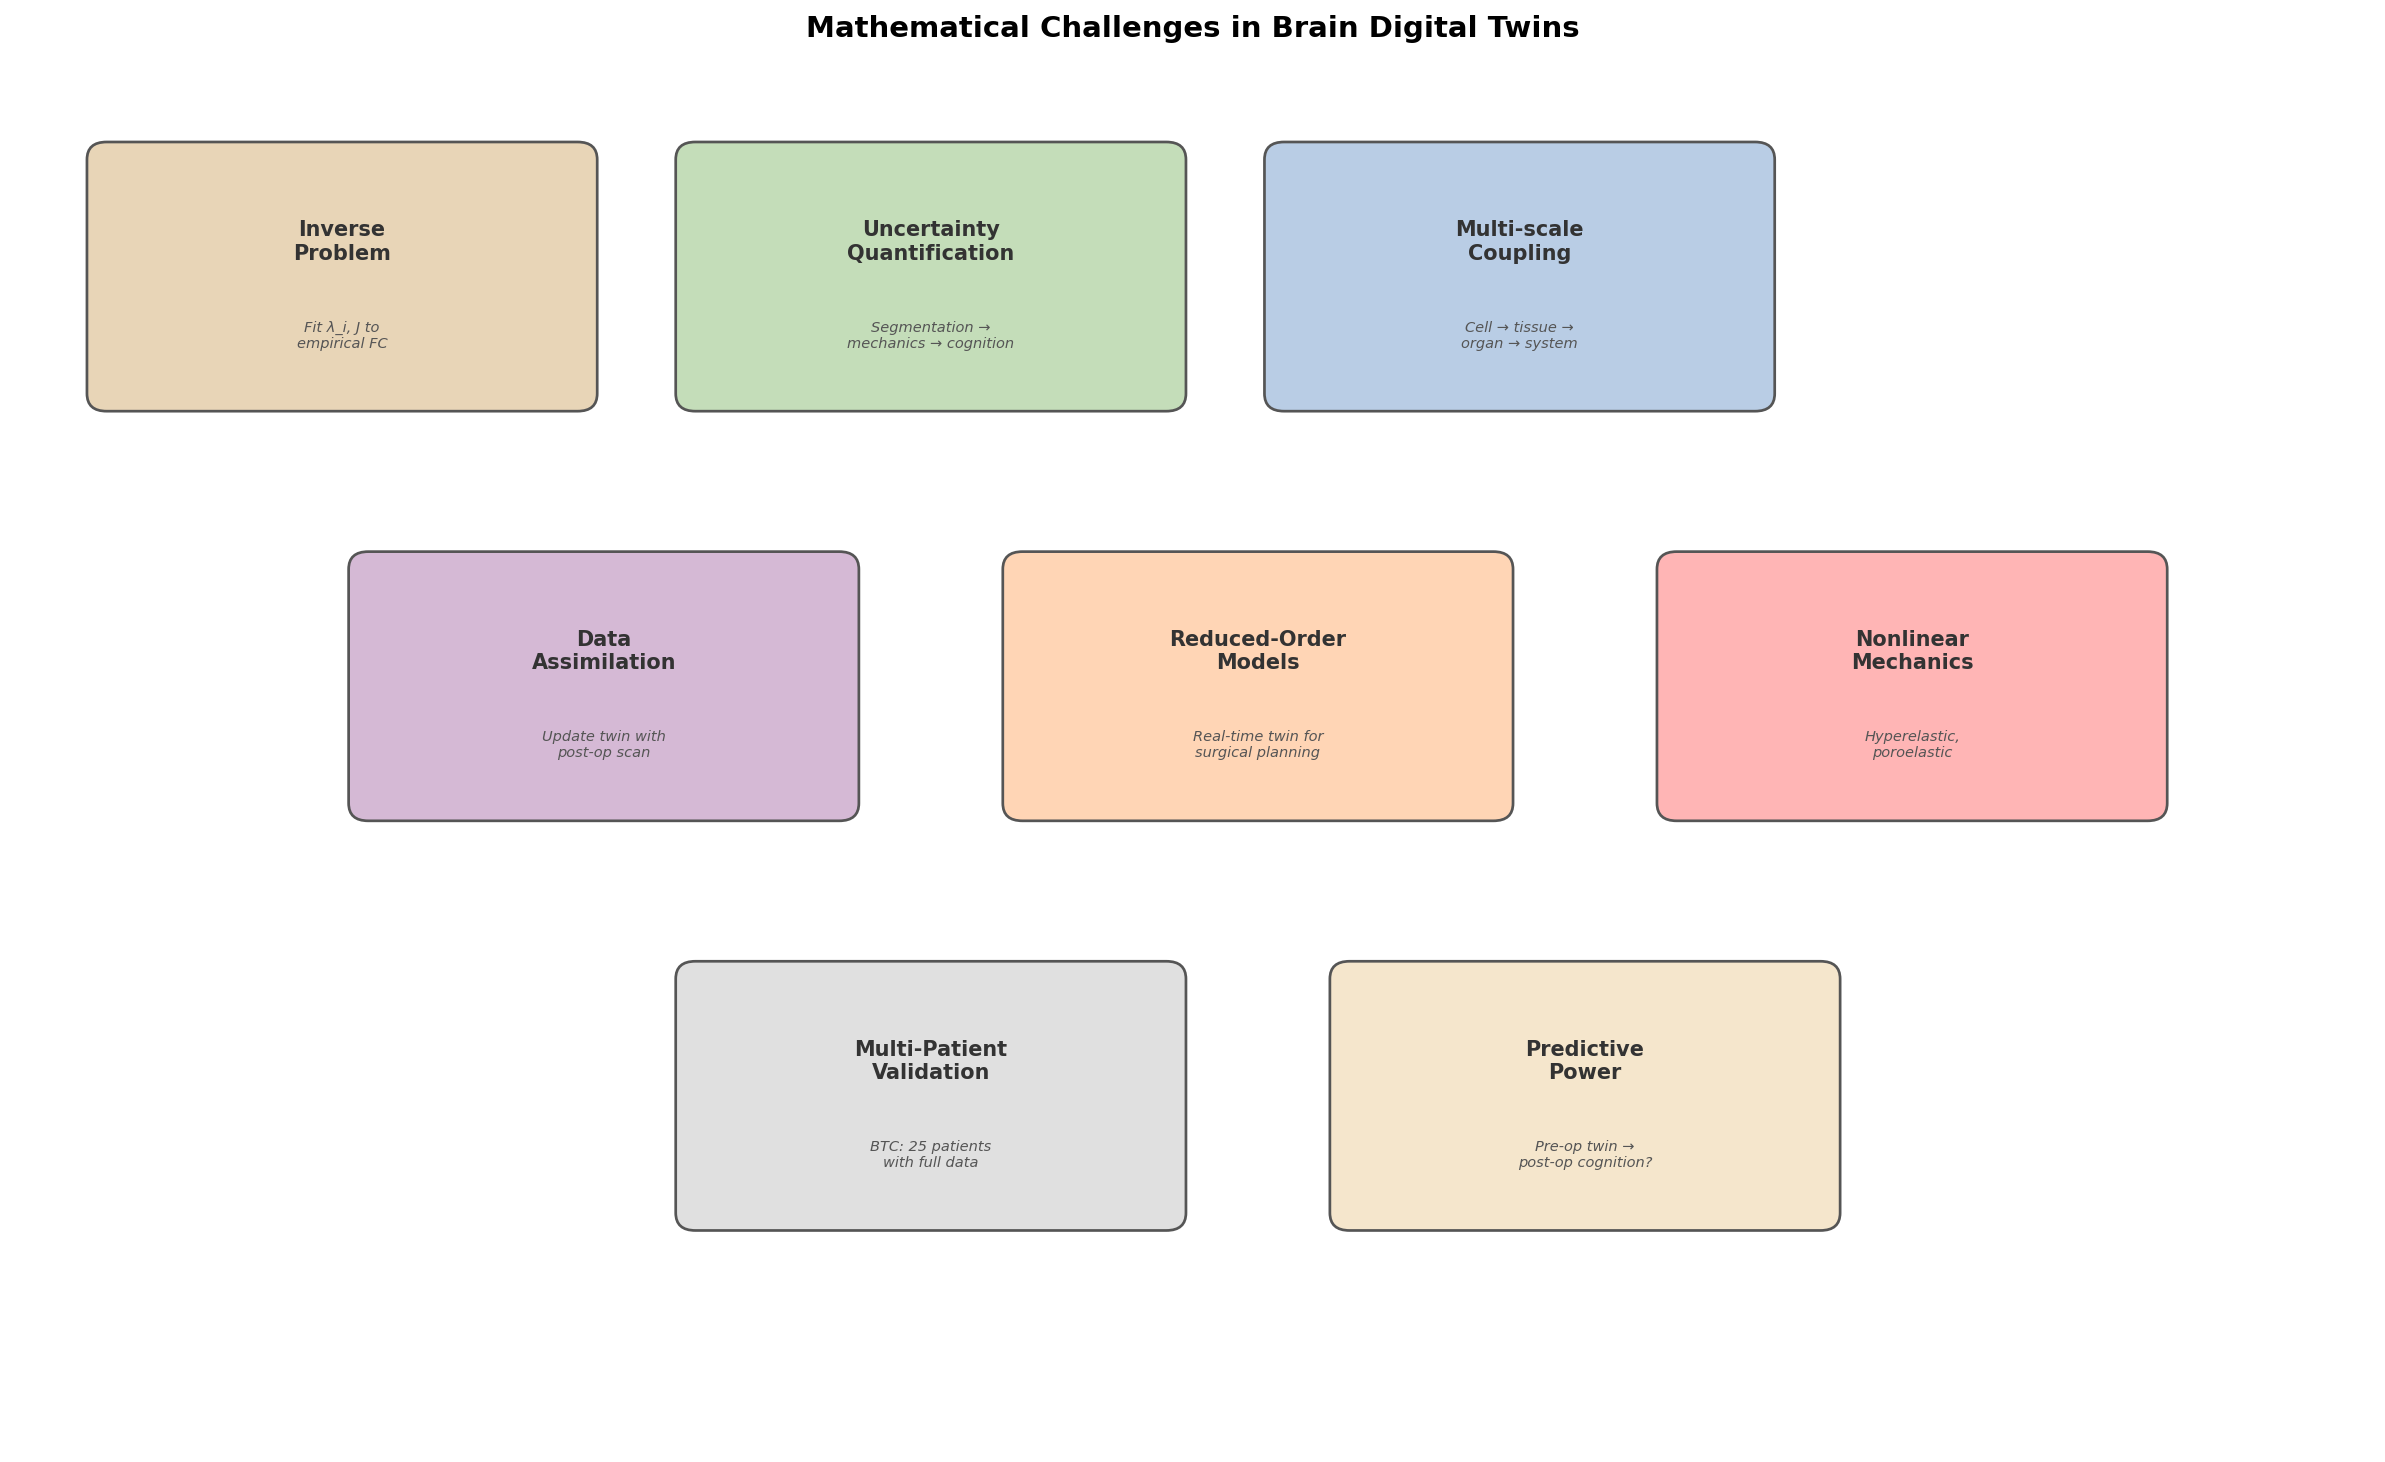

In [3]:
fig, ax = plt.subplots(figsize=(16, 10))
ax.set_xlim(-1, 17)
ax.set_ylim(-1, 11)
ax.axis('off')
fig.suptitle('Mathematical Challenges in Brain Digital Twins',
             fontsize=14, fontweight='bold', y=0.97)

challenges = [
    (1.5, 9.0, 'Inverse\nProblem', '#E8D5B7',
     'Fit \u03bb_i, J to\nempirical FC'),
    (6.0, 9.0, 'Uncertainty\nQuantification', '#C4DDB9',
     'Segmentation \u2192\nmechanics \u2192 cognition'),
    (10.5, 9.0, 'Multi-scale\nCoupling', '#B9CDE5',
     'Cell \u2192 tissue \u2192\norgan \u2192 system'),
    (3.5, 5.5, 'Data\nAssimilation', '#D5B9D5',
     'Update twin with\npost-op scan'),
    (8.5, 5.5, 'Reduced-Order\nModels', '#FFD5B5',
     'Real-time twin for\nsurgical planning'),
    (13.5, 5.5, 'Nonlinear\nMechanics', '#FFB5B5',
     'Hyperelastic,\nporoelastic'),
    (6.0, 2.0, 'Multi-Patient\nValidation', '#E0E0E0',
     'BTC: 25 patients\nwith full data'),
    (11.0, 2.0, 'Predictive\nPower', '#F5E6CC',
     'Pre-op twin \u2192\npost-op cognition?'),
]

for (x, y, title, color, desc) in challenges:
    rect = FancyBboxPatch((x - 1.8, y - 1.0), 3.6, 2.0,
                          boxstyle='round,pad=0.15', facecolor=color,
                          edgecolor='#555', lw=1.3)
    ax.add_patch(rect)
    ax.text(x, y + 0.3, title, ha='center', va='center',
            fontsize=10, fontweight='bold', color='#333')
    ax.text(x, y - 0.5, desc, ha='center', va='center',
            fontsize=7, color='#555', fontstyle='italic')

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC09_01_math_challenges.png', bbox_inches='tight')
plt.show()

---
## 4. AI-Assisted Discovery of Governing Equations

A natural next mathematical perspective is to ask whether the twin should
not only **simulate from assumed equations**, but also help **discover
reduced governing equations from data**. In other words: can AI help infer
which dynamical laws best explain physical or physiological phenomena that
are observed through time-resolved imaging, physiological monitoring, or
controlled intervention? The answer is increasingly **yes**, but only if we
are careful about what kind of equation is being discovered and at what
level of description.

This is important for the glioma brain digital twin because our current
pipeline already contains several partially mechanistic links, but some of
those links are still heuristic. Equation discovery offers a possible
middle ground between black-box prediction and hand-written biophysical
models.

### 4.1 What equation discovery means in this setting

In the present context, equation discovery does **not** mean that AI can
magically recover the full microscopic laws of brain tissue from MRI alone.
It means something more realistic and more useful: from noisy observations
of evolving fields or network states, AI can help identify a **compact,
interpretable dynamical surrogate** such as:

- an ODE for regional state variables
- a PDE for a spatial field such as deformation, oxygenation, diffusion, or tumour cell density
- a stochastic or controlled dynamical system with explicit forcing terms
- a reduced-order closure law that links scales already present in the twin

The most important idea is that the learned equation should remain
**interpretable enough to test, falsify, and couple** with the rest of the
mechanistic twin.

### 4.2 Why AI helps

Classical system identification needs derivatives, low noise, and a small
candidate model class. Brain data rarely satisfy those conditions. MRI,
fMRI, tractography, behavioural trajectories, and postoperative follow-up
are all noisy, indirect, irregularly sampled, and often scarce.

AI helps in three complementary ways:

- **Sparse discovery** can search a large dictionary of candidate terms and keep only a parsimonious subset, as in the SINDy line of work.
- **Physics-informed learning** can fit latent fields, estimate derivatives more stably, and enforce structural constraints when data are scarce or noisy.
- **Representation learning** can map high-dimensional images into lower-dimensional coordinates where a simpler dynamical law becomes visible.

This is exactly why the three references you flagged fit together so well.
They are not identical methods, but they define a common agenda: use data
to discover equations while preserving enough structure that the result is
still meaningful as science rather than only prediction.

### 4.3 Three relevant methodological lines

**Sparse identification of nonlinear dynamics (SINDy).** The SINDy idea is
to assume that the true dynamics are sparse in a candidate library and then
identify only the active terms. In practice, this turns equation discovery
into a sparse regression problem. For digital twins, the attraction is
clear: if the right state variables are available, SINDy can produce
compact candidate equations that are readable by humans and can be tested
against known physics or physiology.

**Physics-based discovery under scarce and noisy data.** A second line of
work combines neural networks, automatic differentiation, sparse
regression, and explicit physical constraints. The key advantage is not
only flexibility, but robustness when measurements are incomplete, noisy,
or too sparse for direct finite-difference derivative estimates. This is
highly relevant in medicine, where data are expensive and repeat sampling
is limited.

**Imaging-derived PDE phenotypes.** The fMRI PDE-phenotype work is
especially interesting for this notebook because it does not treat the
learned PDE only as a simulator. It treats PDE coefficients as
**patient-level or subject-level features** that summarize hidden dynamical
structure. That is a useful conceptual bridge for our twin: a discovered
law can serve not only forward prediction, but also mechanistic
phenotyping.

### 4.4 Where equation discovery could enter the glioma twin

Within our current framework, AI-assisted equation discovery is most
promising where we already have longitudinal or multimodal observations but
not yet a well-identified mechanistic closure.

| Twin component | Possible discovered law | Candidate observations | Potential payoff | Main risk |
|---|---|---|---|---|
| **Tumour evolution** | reaction-diffusion or advection-reaction PDE | serial structural MRI, segmentation, edema maps | patient-specific growth/invasion surrogate | treatment effects and imaging bias confound the law |
| **Brain mechanics** | constitutive or reduced displacement law | pre/post MRI, registration-derived displacement, MRE if available | better closure than heuristic FA $\to E$ mapping | inverse problem is severely ill-posed |
| **Functional dynamics** | regional ODE / neural-mass closure / field equation | rs-fMRI, EEG/MEG, task responses | replace heuristic bifurcation shifts with fitted dynamics | BOLD is indirect and slow |
| **Perfusion / oxygenation / edema** | transport or reaction-diffusion PDE | ASL, DSC/DCE MRI, BOLD, diffusion, longitudinal edema evolution | mechanistic biomarkers of tissue stress and recovery | latent variables are only partially observed |
| **Rehabilitation and recovery** | controlled dynamical system with intervention terms | longitudinal cognition, symptoms, therapy history | distinguish spontaneous recovery from treatment response | sampling is sparse and behavior is multidetermined |

### 4.5 Natural course versus intentional perturbation

Your distinction between **natural course** and **intentional perturbation**
is mathematically crucial.

In the natural course setting, one tries to infer the latent dynamics from
passive observation: tumour progression, spontaneous recovery,
postoperative reorganisation, evolving edema, or resting-state fluctuations
observed over time. This is valuable, but often weakly identifiable,
because many models can explain the same unforced trajectory.

Intentional perturbations are often more informative. In the brain digital
twin context, perturbations may include:

- surgery and resection cavity formation
- task-based fMRI paradigms
- direct electrical stimulation, TMS, or tDCS
- medication changes
- rehabilitation or cognitive training blocks

These perturbations act like **system-identification experiments**. They
make causality easier to probe because the system is driven away from its
baseline and the transient response becomes observable. For the twin, this
suggests a very important design principle: whenever possible, equation
discovery should be posed as a **controlled inverse problem**, not only as
passive curve fitting.

### 4.6 What would count as success in a brain digital twin

For this project, success would not be the claim that AI has recovered the
one true governing equation of the brain. That standard is unrealistic.
Instead, success would be more modest and more rigorous:

- discover a reduced law that is stable across nearby measurements and preprocessing choices
- show that its coefficients carry interpretable patient-specific information
- demonstrate that coupling this law into the twin improves prediction or mechanistic explanation relative to simpler baselines
- quantify uncertainty so that non-identifiability is visible rather than hidden
- test whether the same learned structure survives across patients, while allowing patient-specific coefficients

This is a useful way to think about mechanistic AI: not as a replacement
for physics, but as a tool for discovering the **right level of reduced
physics** for a given measurement regime.

### 4.7 Main cautions

Equation discovery in biomedicine can fail in ways that look persuasive.
The main dangers are:

- discovering equations for the measurement process rather than the underlying biology
- obtaining unstable derivatives from noisy imaging data
- confusing low-dimensional embeddings with true physiological state variables
- over-interpreting coefficients that are predictive but not mechanistically unique
- ignoring intervention, treatment, and boundary conditions that change the apparent law

For that reason, discovered equations should be treated as **hypotheses to
be stress-tested**, not as automatic truth.

### 4.8 The mathematical perspective for this notebook

Placed inside the glioma brain digital twin program, AI-assisted discovery
of governing equations should be viewed as a new intermediate layer between
raw observation and hand-built mechanistic modeling.

- It can help turn longitudinal imaging into compact dynamical hypotheses.
- It can supply reduced constitutive or transport laws where first-principles detail is unavailable.
- It can create new mechanistic phenotypes through discovered coefficients.
- It can improve identifiability when the twin is probed by controlled perturbation rather than only passive observation.

This makes equation discovery highly relevant to the future of the twin,
but also clarifies its role. The goal is not to abandon mechanics,
physiology, or neural modeling in favor of generic AI. The goal is to use
AI to infer better reduced laws, then embed those laws back into a
transparent multiscale framework.

In that sense, equation discovery is one of the clearest examples of how
AI can support a **mathematical** brain digital twin rather than merely a
predictive one.

---
## 5. What the Series Supports, and What It Does Not Yet Support

### What is evidence-based here

The capstone series supports several concrete claims.

- A patient-specific glioma twin can be assembled end-to-end from anatomy,
  diffusion MRI, resting-state fMRI, mechanics, neural dynamics, and
  postoperative clinical outcome.
- The mechanics model captures an important part of the post-surgical brain
  shift problem: adding the mass-effect mechanism substantially reduces the
  displacement mismatch.
- Domain-level structural vulnerability can be compared meaningfully with
  observed postoperative cognition in a way that makes agreement,
  resilience, and mismatch visible.
- Psychosocial burden is not peripheral noise. It is part of the real
  interpretation problem for cognition in glioma.

### What remains provisional

This notebook is still a **single-patient proof-of-concept**. Important
parts of the chain remain simplified.

- the mechanics-to-SC and mechanics-to-excitability links are heuristic
- the Hopf parameters are not yet patient-fitted
- the parcel-to-domain mapping is broad rather than network-optimal
- the twin has not yet been shown to generalize across patients
- the chain does not yet propagate uncertainty from one layer to the next

### What would count as stronger validation

A more convincing digital twin would require at least some of the
following:

- multi-patient out-of-sample testing in the BTC cohort
- sensitivity analysis and uncertainty propagation across the chain
- comparison against simpler baselines that ignore mechanics or dynamics
- prospective use of pre-op data to test post-op predictive value

The aim is therefore not to claim that PAT16 already proves clinical
prediction. The aim is to show that glioma provides an unusually rich test
bed in which patient-specific anatomy, mechanics, networks, behavior, and
psychosocial context can be studied together.

---
## 6. Research Roadmap: From Proof-of-Concept to Clinical Use

The roadmap below should be read as a **research program**, not as a
promise that clinical decision support is already within reach. The key
question is not simply how to make the current pipeline larger, but how to
make it more identifiable, more robust, and more useful.

### Short-term (this workshop and immediate follow-up)
- consolidate the end-to-end PAT16 proof-of-concept
- identify the strongest and weakest assumptions in the coupling chain
- provide a framework that other groups can inspect, critique, and extend

### Medium-term (1--2 years)
- fit per-region neural parameters more rigorously
- extend the mechanics model beyond linear elasticity where needed
- validate on multiple patients from the BTC dataset
- quantify uncertainty rather than reporting only point estimates

### Long-term (3--5 years)
- test whether pre-operative twins carry real predictive value for post-op state
- compare candidate surgical or rehabilitation scenarios *in silico*
- explore reduced-order or intra-operative versions of the mechanics model
- evaluate whether the twin changes decisions, not just explanations

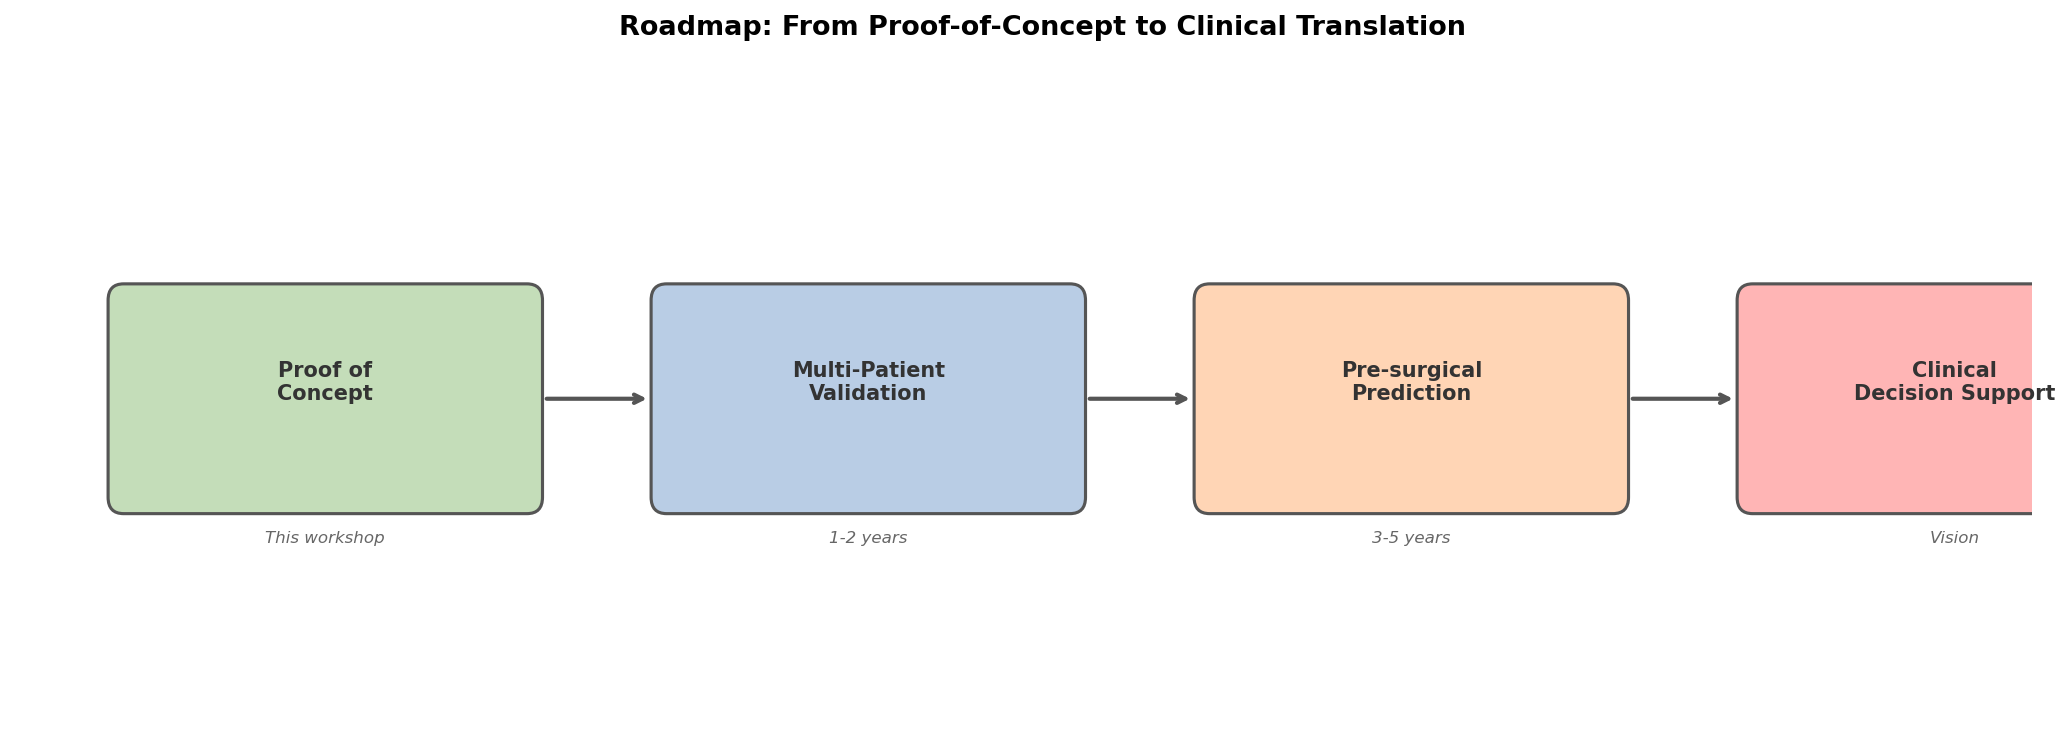

In [4]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.set_xlim(-0.5, 12.5)
ax.set_ylim(-0.5, 3.5)
ax.axis('off')
fig.suptitle('Roadmap: From Proof-of-Concept to Clinical Translation',
             fontsize=13, fontweight='bold')

phases = [
    (1.5, 1.5, 'Proof of\nConcept', 'This workshop', '#C4DDB9'),
    (5.0, 1.5, 'Multi-Patient\nValidation', '1-2 years', '#B9CDE5'),
    (8.5, 1.5, 'Pre-surgical\nPrediction', '3-5 years', '#FFD5B5'),
    (12.0, 1.5, 'Clinical\nDecision Support', 'Vision', '#FFB5B5'),
]

for (x, y, label, timeline, color) in phases:
    rect = FancyBboxPatch((x - 1.3, y - 0.6), 2.6, 1.2,
                          boxstyle='round,pad=0.1', facecolor=color,
                          edgecolor='#555', lw=1.5)
    ax.add_patch(rect)
    ax.text(x, y + 0.1, label, ha='center', va='center',
            fontsize=10, fontweight='bold', color='#333')
    ax.text(x, y - 0.8, timeline, ha='center', va='top',
            fontsize=8, fontstyle='italic', color='#666')

for i in range(len(phases) - 1):
    x1 = phases[i][0] + 1.4
    x2 = phases[i+1][0] - 1.4
    ax.annotate('', xy=(x2, 1.5), xytext=(x1, 1.5),
                arrowprops=dict(arrowstyle='->', lw=2, color='#555'))

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC09_02_roadmap.png', bbox_inches='tight')
plt.show()

---
## Summary

### What this capstone series has built

Taken together, `NB_C01` to `NB_C09` build a first patient-specific
**glioma brain digital twin** for PAT16. The series does not stop at one
modality. It links anatomy, diffusion-informed structure and material
heterogeneity, resting-state function, mechanics, neural dynamics, and
postoperative cognition into one interpretable chain.

### Why glioma is a uniquely informative digital-twin problem

Glioma is unusually well suited to this framework because the same patient
can be observed across multiple levels before and after surgery. Tumour
geometry, resection cavity formation, brain shift, tract perturbation,
network reorganisation, cognitive change, and psychosocial burden can all
be measured in one longitudinal case. That makes glioma not only a
clinical problem, but also a powerful systems neuroscience experiment.

### The main mathematical bottlenecks

The strongest remaining challenges are now clear:

- constitutive modeling beyond small-strain linear elasticity
- inverse estimation of tissue and neural parameters
- AI-assisted discovery of reduced governing equations from longitudinal and perturbed data
- uncertainty propagation through the full coupling chain
- validation that moves from qualitative agreement to true prediction
- extension from one patient to a cohort without losing patient specificity

### The most important next experiment

The next decisive step is not simply to add complexity. It is to test
whether a **pre-operative** twin, with quantified uncertainty, predicts any
meaningful part of the **post-operative** state better than simpler
baselines.

> **A glioma brain digital twin is valuable not because it already predicts
> cognition perfectly, but because it provides a structured,
> patient-specific framework in which anatomy, mechanics, networks,
> function, cognition, and psychosocial outcome can be studied together.**

---
## References

- Aerts H et al. (2018). Modeling Brain Dynamics in Brain Tumor Patients Using the Virtual Brain. *eNeuro* 5(3).
- Aerts H et al. (2022). Pre- and post-surgery brain tumor multimodal MRI data. *Scientific Data* 9:676.
- Bica I et al. (2025). Learning image derived PDE-phenotypes from fMRI data. *Brain Informatics* 12:35. https://doi.org/10.1186/s40708-025-00283-w
- Brunton SL, Proctor JL, Kutz JN (2016). Discovering governing equations from data by sparse identification of nonlinear dynamical systems. *PNAS* 113(15):3932--3937. https://www.pnas.org/doi/10.1073/pnas.1517384113
- Budday S et al. (2019). Mechanical characterization of human brain tissue. *Acta Biomaterialia* 48:319--340.
- Deco G et al. (2017). The dynamics of resting fluctuations in the brain. *Nat Rev Neurosci* 18(6):349--364.
- Miga MI et al. (2001). In vivo quantification of a brain deformation model. *IEEE TMI* 20(12):1384--1397.
- Smith DH et al. (1999). High tolerance and delayed elastic response of cultured axons to dynamic stretch injury. *J Neurosci* 19(11):4263--4269.
- Wang et al. (2025). Physics-based discovery of governing equations from scarce and noisy data. *Physical Review E*. https://link.aps.org/doi/10.1103/d4tm-92vb
- Weickenmeier J et al. (2017). Brain stiffness increases with myelin content. *Acta Biomaterialia* 42:265--272.

---
## Capstone Series Complete

| Notebook | Topic |
|----------|-------|
| [NB\_C01](NB_C01_Digital_Twin_Concept_and_Data.ipynb) | Digital twin concept and data landscape |
| [NB\_C02](NB_C02_Clinical_Cognitive_Data.ipynb) | Clinical, cognitive, and psychosocial data |
| [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb) | Structural MRI and segmentation |
| [NB\_C04](NB_C04_Diffusion_MRI_Tractography.ipynb) | Diffusion MRI and tractography |
| [NB\_C05](NB_C05_Resting_State_fMRI.ipynb) | Resting-state fMRI and functional connectivity |
| [NB\_C06](NB_C06_Brain_Mechanics.ipynb) | Brain mechanics and tissue deformation |
| [NB\_C07](NB_C07_Neural_Dynamics.ipynb) | Neural dynamics and mechanics-dynamics coupling |
| [NB\_C08](NB_C08_Closing_the_Loop.ipynb) | Closing the loop: predicted vs observed |
| **NB\_C09** (this) | Synthesis and mathematical perspectives |